In [1]:
import sqlite3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import tt_ind_solve_power

In [2]:
conn = sqlite3.connect('ecommerce.db')

files = {
    'orders': 'olist_orders_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv'
}

for table_name, file_path in files.items():
    df = pd.read_csv(file_path)
    df.to_sql(table_name, conn, if_exists='replace', index=False)
    print(f"Таблица '{table_name}' успешно загружена в базу данных!")

conn.close()
print("\n--- БАЗА ДАННЫХ ИМИТИРОВАНА И ГОТОВА К РАБОТЕ! ---")

Таблица 'orders' успешно загружена в базу данных!
Таблица 'payments' успешно загружена в базу данных!
Таблица 'reviews' успешно загружена в базу данных!

--- БАЗА ДАННЫХ ИМИТИРОВАНА И ГОТОВА К РАБОТЕ! ---


               value
count  103886.000000
mean      154.100380
std       217.494064
min         0.000000
25%        56.790000
50%       100.000000
75%       171.837500
max     13664.080000


,value
count,95905.000000
mean,110.062133
std,72.785054
min,0.000000
25%,54.000000
50%,92.200000
75%,150.580000
max,344.340000


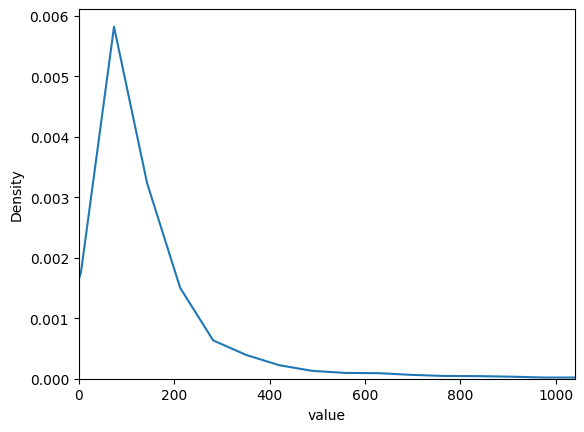

In [3]:
# Описательная статистика и Выбросы
conn = sqlite3.connect('ecommerce.db')

query = """
select payment_value as value
from payments
"""
df_money = pd.read_sql_query(query, conn)
conn.close()

print(df_money.describe())
# график плотности распределения чеков (проверяем на нормальность)
sns.kdeplot(df_money['value'])
plt.xlim(0, df_money['value'].quantile(0.99))

# IQR (межквартильный размах)
q1 = df_money['value'].quantile(0.25)
q3 = df_money['value'].quantile(0.75)
iqr = q3 - q1 # Межквартильный размах
upper_boundary = q3 + 1.5 * iqr # Вычисляем верхнюю границу
df_money_clean = df_money[df_money['value'] <= upper_boundary]
df_money_clean.describe()

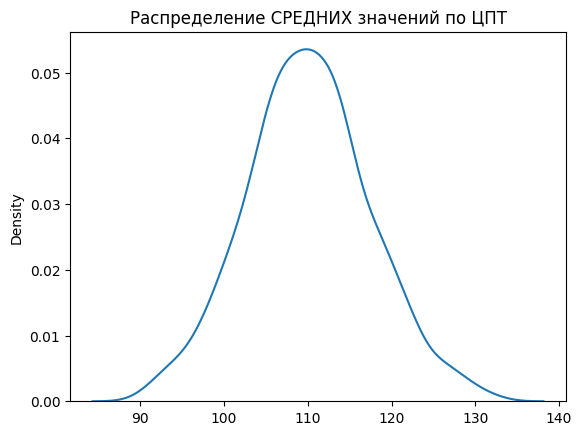

In [4]:
# ЦПТ (Центральной предельной теоремы)
sample_means = []
for i in range(1000):
    random_gr = df_money_clean['value'].sample(100)
    current_mean = random_gr.mean()
    sample_means.append(current_mean)

sns.kdeplot(sample_means)
plt.title('Распределение СРЕДНИХ значений по ЦПТ')
plt.show()

In [5]:
# Расчет количество выборки для проверки увеличения среднегео чека на 5
mde = 5
std = 72.78
ef_z = mde / std
alph = 0.05
pwr = 0.8
sample_size = tt_ind_solve_power(
    effect_size=ef_z, 
    alpha=alph,
    power=pwr, 
    nobs1=None,
    alternative='two-sided'
)
print("Необходимый размер выборки на одну группу:", sample_size)

Необходимый размер выборки на одну группу: 3326.948807948647


In [6]:
# Биноменальное распределиение, покупка / отзыв
conn = sqlite3.connect('ecommerce.db')

query = """
select order_id,
    review_id
from orders o 
    left join reviews r using(order_id)
"""
df_bin = pd.read_sql_query(query, conn)
conn.close()

count_order = 99992
count_review = 99224
p_real = count_review / count_order

prob_100 = stats.binom.pmf(k=100, n=100, p=p_real)
prob_100

np.float64(0.46253815529873094)